# 04 · Models and evaluation
**Owner:** Kasula Lalithendra

1. **train**: tune Logistic Regression, Random Forest and Gradient Boosting with GroupKFold (by premise) and class weights
2. **validation**: pick the best model and its decision threshold
3. **test**: evaluate once: precision, recall, F1, confusion matrix, confidence intervals and error analysis

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, precision_recall_curve, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"
warnings.filterwarnings("ignore")

from src.features import add_structured_features, make_preprocessor

SEED = 42
train, validation, test = (add_structured_features(pd.read_csv(PROCESSED / f"{s}.csv"))
                           for s in ["train", "validation", "test"])


def scores(y, pred):
    return {"precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred, zero_division=0),
            "f1": f1_score(y, pred, zero_division=0)}

## 1. Tune on train
GroupKFold keeps all rows of a premise in the same fold. Class weights make the rare valid class count as much as the
invalid one. The full pipeline (TF-IDF included) is re-fitted in every fold.

In [2]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=3000, class_weight="balanced"),
                            {"model__C": [0.1, 1, 10]}, False),
    "Random Forest": (RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
                      {"model__max_depth": [None, 20], "model__min_samples_leaf": [1, 5]}, False),
    "Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
                          {"model__learning_rate": [0.05, 0.1], "model__max_leaf_nodes": [15, 31]}, True),
}

searches = {}
for name, (model, grid, dense) in models.items():
    pipe = Pipeline([("features", make_preprocessor("both", dense=dense)), ("model", model)])
    searches[name] = GridSearchCV(pipe, grid, cv=GroupKFold(5), scoring="f1", n_jobs=-1)
    searches[name].fit(train, train["label"], groups=train["premise_id"])
    print(f"{name:<20} best CV F1 = {searches[name].best_score_:.3f}  {searches[name].best_params_}")

Logistic Regression  best CV F1 = 0.829  {'model__C': 10}


Random Forest        best CV F1 = 0.911  {'model__max_depth': None, 'model__min_samples_leaf': 1}


Gradient Boosting    best CV F1 = 0.918  {'model__learning_rate': 0.1, 'model__max_leaf_nodes': 31}


## 2. Pick the model on validation

In [3]:
val_proba = {name: s.predict_proba(validation)[:, 1] for name, s in searches.items()}
val_table = pd.DataFrame({name: scores(validation["label"], p >= 0.5) for name, p in val_proba.items()}).T.round(3)
val_table

,precision,recall,f1
Logistic Regression,0.714,0.891,0.793
Random Forest,0.828,0.969,0.893
Gradient Boosting,0.810,0.860,0.835


In [4]:
best = val_table["f1"].idxmax()
precision, recall, thresholds = precision_recall_curve(validation["label"], val_proba[best])
f1 = 2 * precision * recall / np.clip(precision + recall, 1e-9, None)
threshold = thresholds[np.argmax(f1[:-1])]
print(f"chosen model: {best}, threshold: {threshold:.3f}")

chosen model: Random Forest, threshold: 0.607


We take the model with the best validation F1 and the threshold that maximises F1 on validation. Nothing changes after this point.

## 3. Final results on test

In [5]:
test_proba = {name: s.predict_proba(test)[:, 1] for name, s in searches.items()}
test_pred = (test_proba[best] >= threshold).astype(int)

results = {name: scores(test["label"], p >= (threshold if name == best else 0.5)) for name, p in test_proba.items()}
results["Symbolic rule (no learning)"] = scores(test["label"], test["mec_support"] == 1)
pd.DataFrame(results).T.round(3)

,precision,recall,f1
Logistic Regression,0.789,0.933,0.855
Random Forest,0.928,0.928,0.928
Gradient Boosting,0.890,0.989,0.937
Symbolic rule (no learning),0.920,0.828,0.871


The model was chosen on validation, so we keep it even if another one scores slightly higher on test.

### 95% confidence intervals
We resample whole test premises 1,000 times (bootstrap by premise), because rows from the same premise are not independent.

In [6]:
rng = np.random.default_rng(SEED)
premise_ids = test["premise_id"].unique()
rows_of = {pid: np.flatnonzero(test["premise_id"] == pid) for pid in premise_ids}
boot = []
for _ in range(1000):
    idx = np.concatenate([rows_of[p] for p in rng.choice(premise_ids, len(premise_ids))])
    boot.append(scores(test["label"].values[idx], test_pred[idx]))
boot = pd.DataFrame(boot)
pd.DataFrame({"estimate": scores(test["label"], test_pred),
              "lower": boot.quantile(0.025), "upper": boot.quantile(0.975)}).round(3)

,estimate,lower,upper
precision,0.928,0.875,0.969
recall,0.928,0.880,0.968
f1,0.928,0.893,0.957


### Confusion matrices

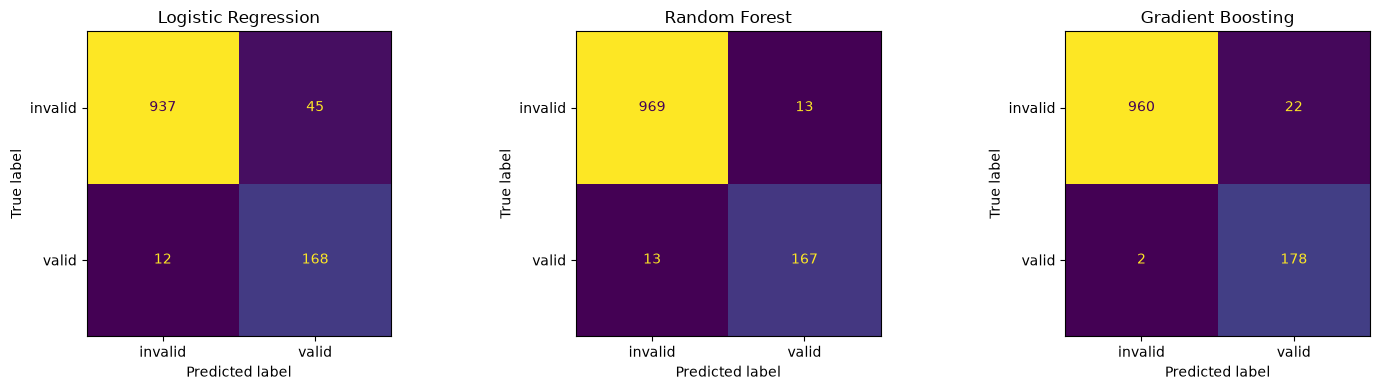

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, p) in zip(axes, test_proba.items()):
    ConfusionMatrixDisplay.from_predictions(test["label"], p >= (threshold if name == best else 0.5),
                                            display_labels=["invalid", "valid"], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 4. Error analysis by hypothesis type

In [8]:
errors = test[["template", "num_variables", "hypothesis", "label"]].assign(pred=test_pred, proba=test_proba[best])
by_type = errors.groupby("template")[["label", "pred"]].apply(lambda d: pd.Series({
    **scores(d["label"], d["pred"]),
    "false alarms": ((d["pred"] == 1) & (d["label"] == 0)).sum(),
    "misses": ((d["pred"] == 0) & (d["label"] == 1)).sum(),
}))
by_type.round(3)

,precision,recall,f1,false alarms,misses
template,,,,,
child,0.000,0.000,0.000,0.0,0.0
has_collider,0.953,0.953,0.953,3.0,3.0
has_confounder,1.000,0.778,0.875,0.0,4.0
non-child descendant,1.000,0.727,0.842,0.0,3.0
non-parent ancestor,0.905,0.864,0.884,2.0,3.0
parent,0.890,1.000,0.942,8.0,0.0


* "child" claims are never valid, so their F1 is 0 by definition. The model makes no mistakes on them.
* Most false alarms are "parent" claims: PC says the arrow must exist, but the dataset labels it 0 (the same cases seen in notebook 02).
* Confounder and indirect-cause claims are rarely valid, so their errors are mostly misses.

In [9]:
# the most confident mistakes
errors[errors["pred"] != errors["label"]].sort_values("proba", key=lambda p: (p - threshold).abs(), ascending=False).head(5)

,template,num_variables,hypothesis,label,pred,proba
1056,parent,6,B directly causes E.,0,1,0.993333
285,non-child descendant,5,"A is a cause for D, but not a direct one.",1,0,0.233333
920,has_confounder,6,"There exists at least one confounder (i.e., co...",1,0,0.253333
705,parent,6,B directly causes F.,0,1,0.956667
232,non-parent ancestor,5,B causes something else which causes D.,1,0,0.280000


## 5. Save test predictions for notebook 05

In [10]:
out = test[["premise_id", "hypothesis", "template", "label"]].assign(proba=test_proba[best], pred=test_pred)
out.to_csv(PROCESSED / "test_predictions.csv", index=False)
print("saved data/processed/test_predictions.csv")

saved data/processed/test_predictions.csv
